## Attempt at finite difference method

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

L = 1
 
u(0,t) = 0
u(1,t) = 100

In [ ]:
deltatime = 0.25
deltaspace = 0.025
alpha = 1.22*10*10**-4
constant = alpha*(deltatime/(deltaspace)**2)
time = np.linspace(0,270,1080)
space = np.linspace(0,1,40)
pattern = []
u_new = np.zeros(40)
u_0 = np.array([100,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0])
for j in time:
    for i in range(len(space)):
        if i == 0:
            u_new[i] = 100
            continue
        elif i ==39:
            u_new[i] = u_0[i] + 2*constant* (u_0[i-1] - u_0[i])
            continue
        else:
            u_new[i] = constant*(u_0[i+1] - 2*u_0[i] + u_0[i-1]) + u_0[i]
    print(u_0)
    pattern.append(u_0)
    u_0 = u_new.copy()
    


[100   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0]
[100.   48.8   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0. ]
[100.      49.9712  23.8144   0.       0.       0.       0.       0.
   0.       0.       0.       0.       0.       0.       0.       0.
   0.       0.       0.       0.       0.       0.       0.       0.
   0.       0.       0.       0.       0.       0.       0.       0.
   0.       0.       0.       0.       0.       0.       0.       0.    ]
[100.         61.620736   24.9574912  11.6214272   0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.     

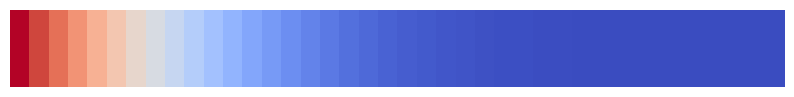

In [19]:
plt.figure(figsize=(10, 1))
plt.imshow([pattern[100]], cmap="coolwarm", aspect="auto")  # blue -> red
plt.axis("off")
plt.show()

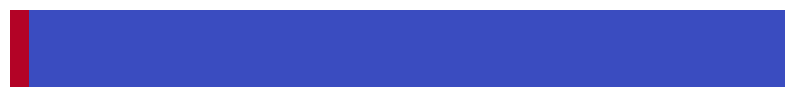

In [ ]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation
fig, ax = plt.subplots(figsize=(10, 1))

img = ax.imshow([pattern[0]], cmap="coolwarm",
                vmin=0, vmax=100,
                aspect="auto")

ax.axis("off")

def update(frame):
    img.set_data([pattern[frame]])
    return [img]

ani = FuncAnimation(
    fig,
    update,
    frames=len(pattern),
    interval=10
)

HTML(ani.to_jshtml())